cropped_64x64_permilX/ディレクトリを作成します．
Xはパーミル値です．

変換するファイルは
file_id = "223_48_1.png"
と指定してください．


cropped_64x64_permil1/223_48_1.png


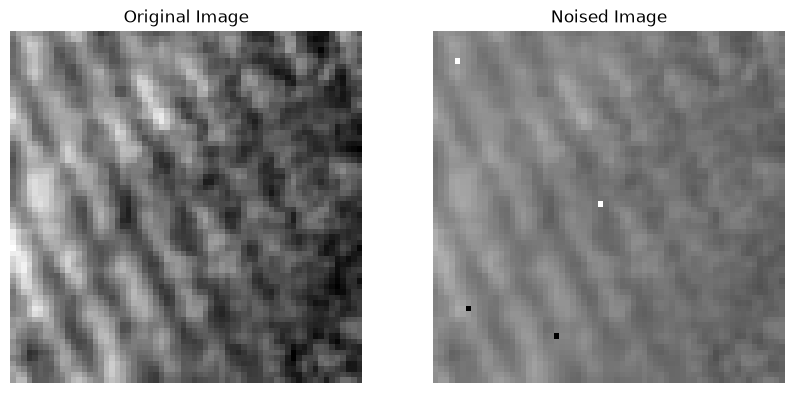

Noised image saved as 'cropped_64x64_permil1/223_48_1.png'
cropped_64x64_permil3/223_48_1.png


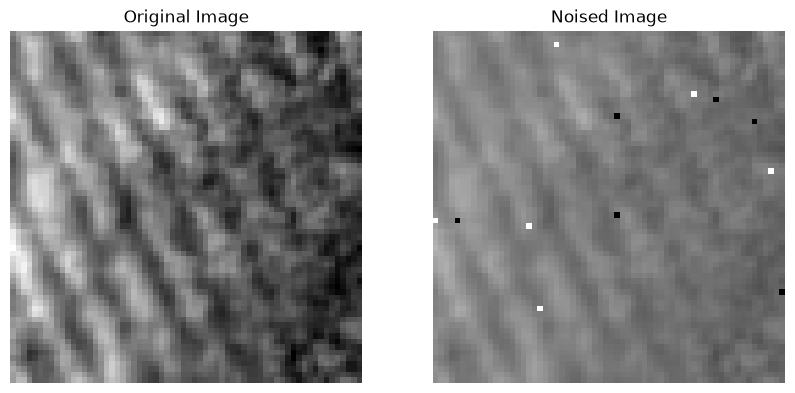

Noised image saved as 'cropped_64x64_permil3/223_48_1.png'
cropped_64x64_permil5/223_48_1.png


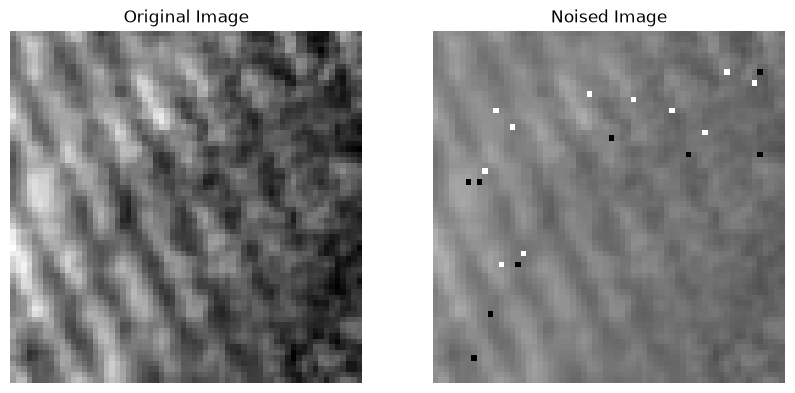

Noised image saved as 'cropped_64x64_permil5/223_48_1.png'
cropped_64x64_permil10/223_48_1.png


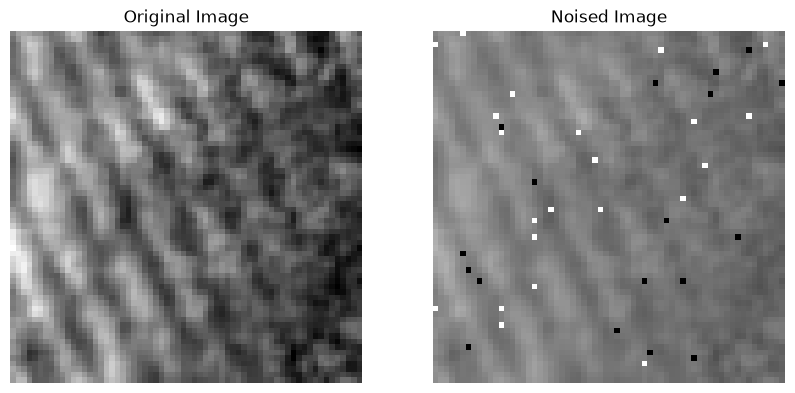

Noised image saved as 'cropped_64x64_permil10/223_48_1.png'
cropped_64x64_permil30/223_48_1.png


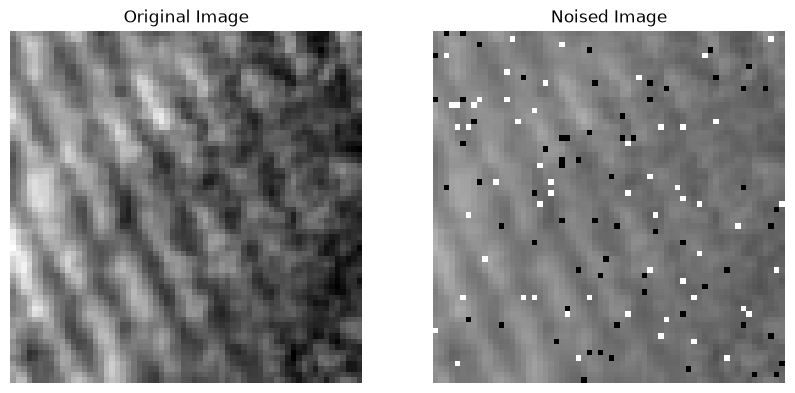

Noised image saved as 'cropped_64x64_permil30/223_48_1.png'
cropped_64x64_permil50/223_48_1.png


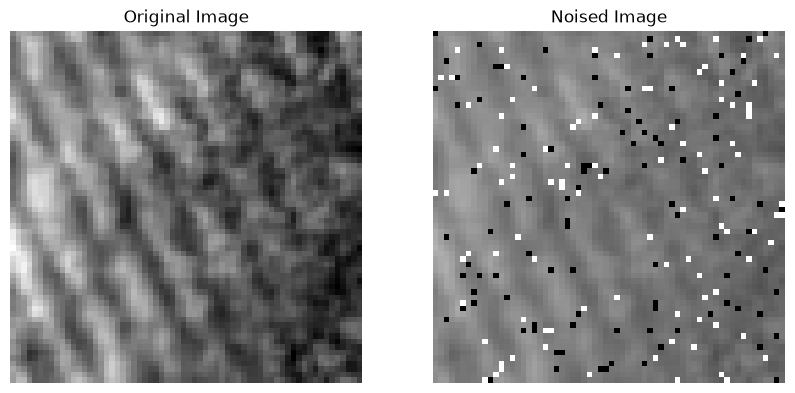

Noised image saved as 'cropped_64x64_permil50/223_48_1.png'
cropped_64x64_permil100/223_48_1.png


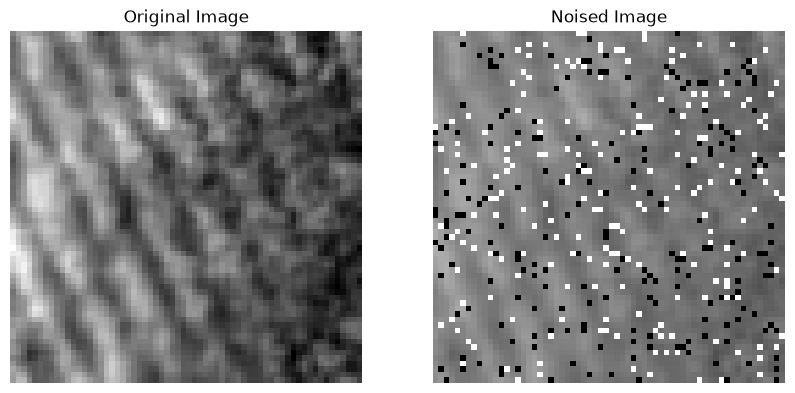

Noised image saved as 'cropped_64x64_permil100/223_48_1.png'


In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

def add_noise(img_filename, noisedimg_filename, ratio):
    # 画像を読み込む
    img = Image.open(img_filename).convert('L')
    img_array = np.array(img)
    
    # 画像の次元サイズを取得
    height, width = img_array.shape
    
    # ノイズを付加するピクセル数を計算
    num_noisy_pixels = int(height * width * ratio)
    
    # ランダムなピクセル位置を生成
    noisy_indices = np.random.choice(height * width, num_noisy_pixels, replace=False)
    
    # 元の画像を平坦化
    flat_img = img_array.flatten()
    
    # ノイズを追加
    flat_img[noisy_indices] = np.random.choice([0, 255], num_noisy_pixels)
    
    # 改めて画像の形状に戻す
    noised_img_array = flat_img.reshape(height, width)
    
    # 画像を保存
    noised_img = Image.fromarray(noised_img_array)
    noised_img.save(noisedimg_filename)
    
    # 画像を並べて表示
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_array, cmap='gray')
    axes[0].set_title('Original Image')
    axes[0].axis('off')
    
    axes[1].imshow(noised_img_array, cmap='gray')
    axes[1].set_title('Noised Image')
    axes[1].axis('off')
    
    plt.show()
    print(f"Noised image saved as '{noisedimg_filename}'")

# 使用例
# この部分はGPT4oの出力では無い。
import os

def make_noised_file(file_id , source_img_dir = "cropped_64x64", ratio = 0.1):
    img_filename = os.path.join(source_img_dir, file_id)
    percentage = ratio*1000
    output_dir = f"{source_img_dir}_permil{int(percentage)}"
    noised_img_filename = os.path.join(output_dir, file_id)
    print(noised_img_filename)
    os.makedirs(output_dir, exist_ok=True)
    add_noise(img_filename, noised_img_filename, ratio)

for ratio in [0.001, 0.003, 0.005, 0.01, 0.03, 0.05, 0.1]:
    make_noised_file(file_id = "223_48_1.png", source_img_dir = "cropped_64x64", ratio=ratio)